In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

In [2]:
df = pd.read_csv("data/city_day.csv", parse_dates=["Date"])
print(df.shape)
df.head()

(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
h = df[df["City"] == "Hyderabad"].sort_values("Date")

print("Rows:", len(h))
print("Date range:", h["Date"].min(), "to", h["Date"].max())
print("Rows with AQI:", h["AQI"].notna().sum())
print("Rows per year:")
print(h.dropna(subset=["AQI"]).groupby(h["Date"].dt.year).size())

Rows: 2006
Date range: 2015-01-04 00:00:00 to 2020-07-01 00:00:00
Rows with AQI: 1880
Rows per year:
Date
2015    272
2016    337
2017    358
2018    365
2019    365
2020    183
dtype: int64


In [4]:
df = df[df["City"] == "Hyderabad"].sort_values("Date").reset_index(drop=True)

print("Rows and columns:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
df.head()

Rows and columns: (2006, 16)
Date range: 2015-01-04 00:00:00 to 2020-07-01 00:00:00


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Hyderabad,2015-01-04,NaN,NaN,3.70,17.19,20.89,NaN,0.30,2.58,30.34,0.41,6.15,1.11,NaN,NaN
1,Hyderabad,2015-01-05,NaN,NaN,3.61,9.69,13.30,NaN,0.23,5.19,31.28,0.39,7.22,0.55,NaN,NaN
2,Hyderabad,2015-01-06,NaN,NaN,4.21,22.02,26.23,NaN,0.31,9.09,28.56,0.52,5.14,0.53,NaN,NaN
3,Hyderabad,2015-01-07,NaN,NaN,26.08,40.08,66.15,NaN,0.53,9.03,31.08,1.92,16.35,2.14,NaN,NaN
4,Hyderabad,2015-01-08,NaN,NaN,10.31,33.02,43.33,NaN,0.44,8.47,35.72,1.89,14.27,1.58,NaN,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2006 entries, 0 to 2005
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        2006 non-null   str           
 1   Date        2006 non-null   datetime64[us]
 2   PM2.5       1891 non-null   float64       
 3   PM10        1651 non-null   float64       
 4   NO          1978 non-null   float64       
 5   NO2         1978 non-null   float64       
 6   NOx         1999 non-null   float64       
 7   NH3         1646 non-null   float64       
 8   CO          2001 non-null   float64       
 9   SO2         1980 non-null   float64       
 10  O3          1980 non-null   float64       
 11  Benzene     1879 non-null   float64       
 12  Toluene     1879 non-null   float64       
 13  Xylene      1879 non-null   float64       
 14  AQI         1880 non-null   float64       
 15  AQI_Bucket  1880 non-null   str           
dtypes: datetime64[us](1), float64(13), 

In [6]:
print("Missing values (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))
print("Duplicate rows:", df.duplicated().sum())

Missing values (%):
NH3           17.9
PM10          17.7
Benzene        6.3
Toluene        6.3
Xylene         6.3
AQI            6.3
AQI_Bucket     6.3
PM2.5          5.7
NO             1.4
NO2            1.4
SO2            1.3
O3             1.3
NOx            0.3
CO             0.2
City           0.0
Date           0.0
dtype: float64
Duplicate rows: 0


In [7]:
df = df.drop(columns=["City", "AQI_Bucket"])
df.columns

Index(['Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3',
       'Benzene', 'Toluene', 'Xylene', 'AQI'],
      dtype='str')

In [8]:
full_range = pd.date_range(df["Date"].min(), df["Date"].max(), freq="D")
print("Days in calendar:", len(full_range))
print("Days in data:", len(df))
print("Missing dates:", len(full_range.difference(df["Date"])))

Days in calendar: 2006
Days in data: 2006
Missing dates: 0


In [9]:
df.describe().round(1)

,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,2006,1891.0,1651.0,1978.0,1978.0,1999.0,1646.0,2001.0,1980.0,1980.0,1879.0,1879.0,1879.0,1880.0
mean,2017-10-02 12:00:00,47.0,91.9,7.8,28.4,19.4,16.2,0.6,9.2,33.6,1.2,7.9,1.7,109.2
min,2015-01-04 00:00:00,4.8,10.5,1.2,0.6,0.0,2.5,0.0,0.7,0.0,0.0,0.0,0.0,22.0
25%,2016-05-19 06:00:00,25.8,61.5,4.7,15.5,12.5,10.5,0.3,5.4,22.5,0.2,1.6,0.2,75.0
50%,2017-10-02 12:00:00,42.0,94.5,7.0,25.6,17.7,14.4,0.6,7.0,32.1,0.8,4.5,0.7,104.0
75%,2019-02-15 18:00:00,61.4,117.4,9.7,38.9,24.8,19.8,0.8,9.8,43.1,1.6,9.6,1.9,130.0
max,2020-07-01 00:00:00,571.0,485.9,44.6,92.3,97.4,78.6,8.8,70.4,107.7,8.1,60.0,28.2,737.0
std,NaN,38.5,40.5,4.9,15.9,10.7,8.2,0.5,7.3,14.9,1.3,9.4,2.8,53.1


In [10]:
extreme = df[df["AQI"] > 300][["Date", "PM2.5", "PM10", "AQI"]]
print("Days with AQI > 300:", len(extreme))
extreme

Days with AQI > 300: 17


,Date,PM2.5,PM10,AQI
100,2015-04-14,158.32,NaN,312.0
149,2015-06-02,539.13,NaN,661.0
171,2015-06-24,467.67,NaN,348.0
172,2015-06-25,22.75,NaN,342.0
229,2015-08-21,299.25,NaN,316.0
230,2015-08-22,108.69,NaN,390.0
244,2015-09-05,114.41,NaN,305.0
270,2015-10-01,120.75,92.29,340.0
278,2015-10-09,137.28,93.47,316.0
299,2015-10-30,516.20,82.97,487.0


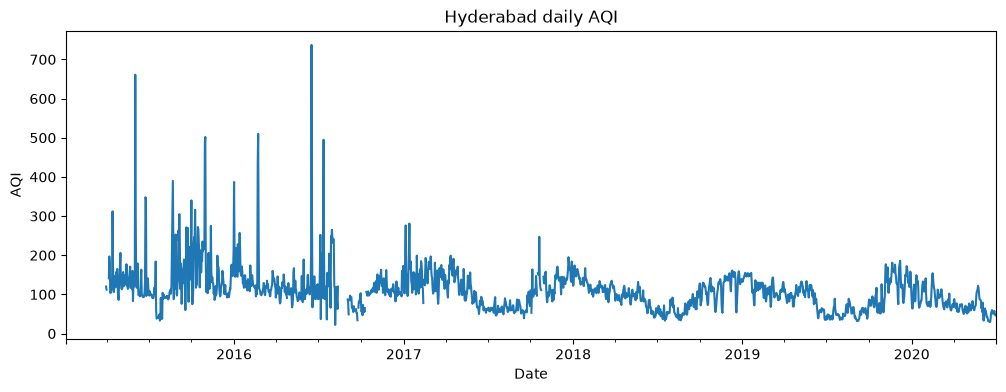

In [11]:
df.set_index("Date")["AQI"].plot(figsize=(12, 4), title="Hyderabad daily AQI")
plt.ylabel("AQI")
plt.show()

In [12]:
missing_by_year = (
    df.drop(columns="Date")
      .isna()
      .groupby(df["Date"].dt.year)
      .mean()
      .mul(100)
      .round(1)
)
missing_by_year

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
Date,,,,,,,,,,,,,
2015,24.9,71.3,0.8,0.8,0.8,72.1,0.8,0.8,0.8,30.9,30.9,30.9,24.9
2016,6.6,25.7,6.6,6.6,1.1,26.8,0.5,6.0,6.0,4.1,4.1,4.1,7.9
2017,0.3,0.8,0.3,0.3,0.0,0.3,0.0,0.3,0.3,0.0,0.0,0.0,1.9
2018,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2020,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
aqi_missing = df["AQI"].isna()
run_id = (aqi_missing != aqi_missing.shift()).cumsum()

gaps = (
    df[aqi_missing]
    .groupby(run_id[aqi_missing])["Date"]
    .agg(start="min", end="max", days="count")
)
gaps.sort_values("days", ascending=False).head(10)

,start,end,days
AQI,,,
1,2015-01-04,2015-03-30,86
7,2016-08-13,2016-09-01,20
3,2015-04-02,2015-04-05,4
25,2017-10-25,2017-10-28,4
13,2016-09-17,2016-09-19,3
17,2016-10-10,2016-10-11,2
5,2016-04-25,2016-04-25,1
9,2016-09-05,2016-09-05,1
11,2016-09-09,2016-09-09,1


In [14]:
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO",
              "SO2", "O3", "Benzene", "Toluene", "Xylene"]

df[pollutants] = df[pollutants].ffill(limit=3)

print("Missing values (%) after filling:")
print((df[pollutants].isna().mean() * 100).round(1).sort_values(ascending=False))

Missing values (%) after filling:
NH3        17.0
PM10       16.7
Benzene     5.7
Toluene     5.7
Xylene      5.7
PM2.5       5.1
NO          0.8
NO2         0.8
SO2         0.8
O3          0.8
NOx         0.0
CO          0.0
dtype: float64


In [15]:
usable = df[df["AQI"].notna()]
print("Rows with AQI:", len(usable))

print("\nMissing % among rows with AQI:")
print((usable[pollutants].isna().mean() * 100).round(1).sort_values(ascending=False))

print("\nMissing % of PM10 and NH3, by year (rows with AQI only):")
print(
    usable.groupby(usable["Date"].dt.year)[["PM10", "NH3"]]
          .apply(lambda g: g.isna().mean() * 100)
          .round(1)
)

Rows with AQI: 1880

Missing % among rows with AQI:
NH3        12.5
PM10       12.2
Benzene     6.0
Toluene     6.0
Xylene      6.0
PM2.5       0.0
NO          0.0
NO2         0.0
NOx         0.0
CO          0.0
SO2         0.0
O3          0.0
dtype: float64

Missing % of PM10 and NH3, by year (rows with AQI only):
      PM10   NH3
Date            
2015  59.2  61.4
2016  20.2  20.2
2017   0.0   0.0
2018   0.0   0.0
2019   0.0   0.0
2020   0.0   0.0


In [16]:
eda = df[df["AQI"].notna()].copy()
eda["year"] = eda["Date"].dt.year
eda["month"] = eda["Date"].dt.month
print(len(eda))

1880


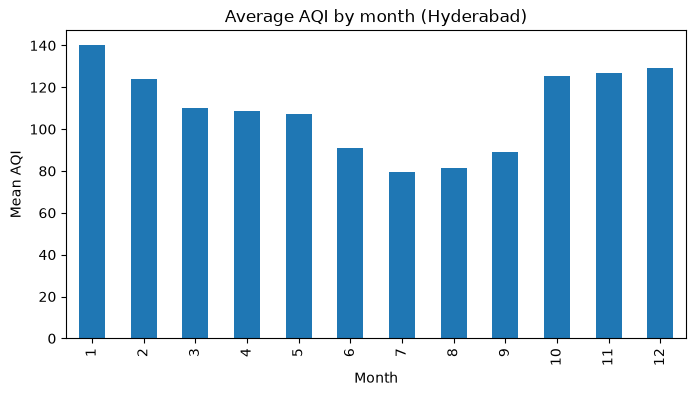

In [17]:
monthly = eda.groupby("month")["AQI"].mean()
monthly.plot(kind="bar", figsize=(8, 4), title="Average AQI by month (Hyderabad)")
plt.xlabel("Month")
plt.ylabel("Mean AQI")
plt.show()

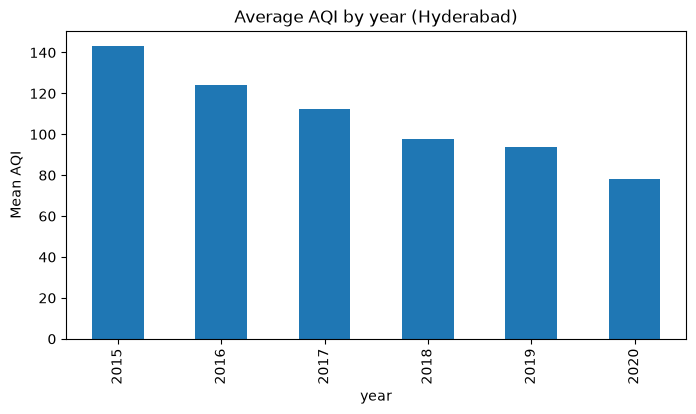

In [18]:
eda.groupby("year")["AQI"].mean().plot(kind="bar", figsize=(8, 4),
                                       title="Average AQI by year (Hyderabad)")
plt.ylabel("Mean AQI")
plt.show()

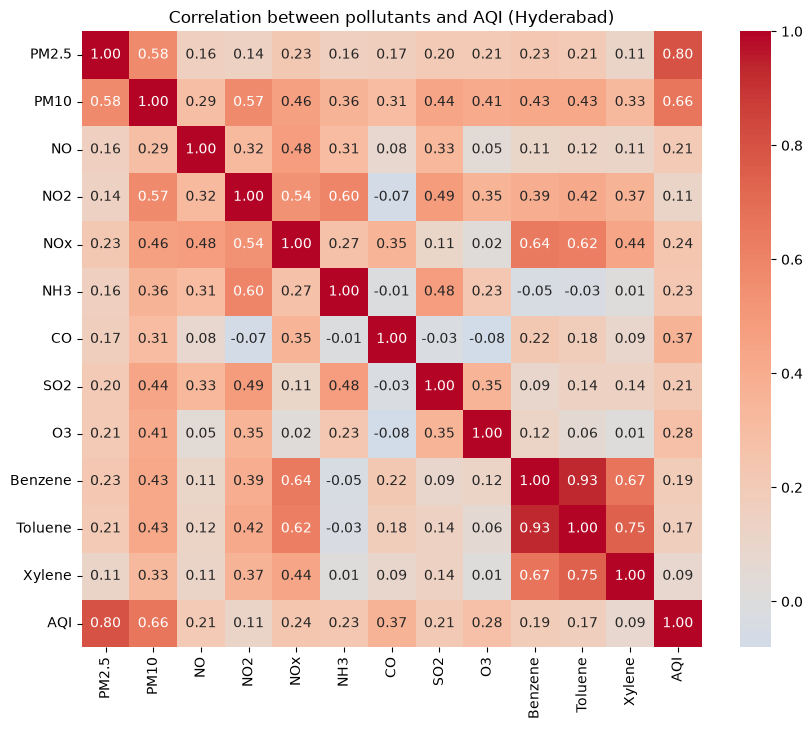

In [19]:
plt.figure(figsize=(10, 8))
sns.heatmap(eda[pollutants + ["AQI"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between pollutants and AQI (Hyderabad)")
plt.show()

In [20]:
df = df.sort_values("Date").reset_index(drop=True)

# Target: tomorrow's AQI
df["target"] = df["AQI"].shift(-1)

# Features from the past
df["AQI_lag1"] = df["AQI"].shift(1)        # yesterday's AQI
df["AQI_lag2"] = df["AQI"].shift(2)        # 2 days ago
df["AQI_lag7"] = df["AQI"].shift(7)        # same weekday last week
df["AQI_roll7"] = df["AQI"].rolling(7).mean()   # average of the last 7 days

# Calendar features
df["month"] = df["Date"].dt.month
df["dayofweek"] = df["Date"].dt.day_of_week

In [21]:
model_df = df.dropna(subset=["target", "AQI", "AQI_lag1", "AQI_lag2",
                             "AQI_lag7", "AQI_roll7"]).reset_index(drop=True)

print("Usable rows:", len(model_df))
model_df[["Date", "AQI", "AQI_lag1", "target"]].head(8)

Usable rows: 1797


,Date,AQI,AQI_lag1,target
0,2015-04-13,133.0,128.0,312.0
1,2015-04-14,312.0,133.0,179.0
2,2015-04-15,179.0,312.0,112.0
3,2015-04-16,112.0,179.0,106.0
4,2015-04-17,106.0,112.0,147.0
5,2015-04-18,147.0,106.0,139.0
6,2015-04-19,139.0,147.0,118.0
7,2015-04-20,118.0,139.0,123.0


In [22]:
features = pollutants + ["AQI", "AQI_lag1", "AQI_lag2", "AQI_lag7",
                         "AQI_roll7", "month", "dayofweek"]

train = model_df[model_df["Date"] < "2019-01-01"]
val   = model_df[(model_df["Date"] >= "2019-01-01") & (model_df["Date"] < "2020-01-01")]
test  = model_df[model_df["Date"] >= "2020-01-01"]

X_train, y_train = train[features], train["target"]
X_val,   y_val   = val[features],   val["target"]
X_test,  y_test  = test[features],  test["target"]

print("Total usable rows:", len(model_df))
for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name}: {len(part)} rows, {part['Date'].min().date()} to {part['Date'].max().date()}")

Total usable rows: 1797
Train: 1250 rows, 2015-04-13 to 2018-12-31
Validation: 365 rows, 2019-01-01 to 2019-12-31
Test: 182 rows, 2020-01-01 to 2020-06-30


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def score(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

results = {}
results["Baseline: persistence"] = score(y_val, X_val["AQI"])
results["Baseline: 7-day average"] = score(y_val, X_val["AQI_roll7"])

pd.DataFrame(results).T.round(2)

,MAE,RMSE,R2
Baseline: persistence,10.18,14.31,0.85
Baseline: 7-day average,15.03,20.33,0.70


In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

models = {
    "Ridge": make_pipeline(SimpleImputer(strategy="median"),
                           StandardScaler(),
                           Ridge(alpha=1.0)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestRegressor(n_estimators=200,
                                                         random_state=42,
                                                         n_jobs=-1)),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05,
                            max_depth=4, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = score(y_val, model.predict(X_val))

pd.DataFrame(results).T.round(2).sort_values("MAE")

,MAE,RMSE,R2
XGBoost,9.29,12.19,0.89
Random Forest,9.37,12.50,0.89
Baseline: persistence,10.18,14.31,0.85
Ridge,12.65,15.44,0.83
Baseline: 7-day average,15.03,20.33,0.70


In [25]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

tscv = TimeSeriesSplit(n_splits=5)

# Tune XGBoost
xgb_grid = GridSearchCV(
    XGBRegressor(random_state=42),
    param_grid={
        "n_estimators": [200, 400],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_depth": [2, 3, 4],
    },
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1)
xgb_grid.fit(X_train, y_train)
print("Best XGBoost params:", xgb_grid.best_params_)
print("XGBoost CV MAE:", round(-xgb_grid.best_score_, 2))

# Tune Random Forest
rf_pipe = make_pipeline(SimpleImputer(strategy="median"),
                        RandomForestRegressor(random_state=42, n_jobs=-1))
rf_grid = GridSearchCV(
    rf_pipe,
    param_grid={
        "randomforestregressor__n_estimators": [200, 400],
        "randomforestregressor__max_depth": [5, 10, None],
        "randomforestregressor__min_samples_leaf": [1, 5],
    },
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=1)
rf_grid.fit(X_train, y_train)
print("Best Random Forest params:", rf_grid.best_params_)
print("Random Forest CV MAE:", round(-rf_grid.best_score_, 2))

Best XGBoost params: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}
XGBoost CV MAE: 22.33
Best Random Forest params: {'randomforestregressor__max_depth': 5, 'randomforestregressor__min_samples_leaf': 5, 'randomforestregressor__n_estimators': 200}
Random Forest CV MAE: 20.26


In [26]:
results["XGBoost (tuned)"] = score(y_val, xgb_grid.best_estimator_.predict(X_val))
results["Random Forest (tuned)"] = score(y_val, rf_grid.best_estimator_.predict(X_val))

pd.DataFrame(results).T.round(2).sort_values("MAE")

,MAE,RMSE,R2
XGBoost,9.29,12.19,0.89
Random Forest,9.37,12.50,0.89
Random Forest (tuned),9.83,12.90,0.88
Baseline: persistence,10.18,14.31,0.85
XGBoost (tuned),10.70,13.82,0.86
Ridge,12.65,15.44,0.83
Baseline: 7-day average,15.03,20.33,0.70


In [27]:
from sklearn.base import clone

recent = train[train["Date"] >= "2017-01-01"]
X_recent, y_recent = recent[features], recent["target"]
print("Recent training rows:", len(recent))

for name, model in models.items():
    m = clone(model)
    m.fit(X_recent, y_recent)
    results[name + " (2017+ only)"] = score(y_val, m.predict(X_val))

pd.DataFrame(results).T.round(2).sort_values("MAE")

Recent training rows: 691


,MAE,RMSE,R2
Random Forest (2017+ only),8.16,11.07,0.91
XGBoost (2017+ only),8.62,11.38,0.91
XGBoost,9.29,12.19,0.89
Ridge (2017+ only),9.33,12.38,0.89
Random Forest,9.37,12.50,0.89
Random Forest (tuned),9.83,12.90,0.88
Baseline: persistence,10.18,14.31,0.85
XGBoost (tuned),10.70,13.82,0.86
Ridge,12.65,15.44,0.83
Baseline: 7-day average,15.03,20.33,0.70


In [28]:
final_train = model_df[(model_df["Date"] >= "2017-01-01") &
                       (model_df["Date"] < "2020-01-01")]
X_final, y_final = final_train[features], final_train["target"]
print("Final training rows:", len(final_train))

final_model = clone(models["Random Forest"])
final_model.fit(X_final, y_final)

test_pred = final_model.predict(X_test)

test_results = {
    "Baseline: persistence": score(y_test, X_test["AQI"]),
    "Random Forest (final)": score(y_test, test_pred),
}
pd.DataFrame(test_results).T.round(2)

Final training rows: 1056


,MAE,RMSE,R2
Baseline: persistence,9.00,12.38,0.78
Random Forest (final),8.94,10.84,0.83


In [29]:
test_eval = test[["Date", "target"]].copy()
test_eval["rf_pred"] = test_pred
test_eval["persist_pred"] = X_test["AQI"].values
test_eval["rf_err"] = (test_eval["target"] - test_eval["rf_pred"]).abs()
test_eval["persist_err"] = (test_eval["target"] - test_eval["persist_pred"]).abs()
test_eval["month"] = test_eval["Date"].dt.month

print("Mean absolute error by month:")
print(test_eval.groupby("month")[["rf_err", "persist_err"]].mean().round(2))

print("\nTen largest Random Forest errors:")
print(test_eval.sort_values("rf_err", ascending=False).head(10).round(1))

Mean absolute error by month:
       rf_err  persist_err
month                     
1       11.31        14.74
2       10.27        10.17
3        8.66         8.10
4        7.70         6.13
5        7.65         7.94
6        8.05         6.83

Ten largest Random Forest errors:
           Date  target  rf_pred  persist_pred  rf_err  persist_err  month
1645 2020-01-31    99.0    132.7         141.0    33.7         42.0      1
1768 2020-06-02    38.0     69.7          79.0    31.7         41.0      6
1646 2020-02-01    77.0    102.7          99.0    25.7         22.0      2
1623 2020-01-09   123.0     98.3          84.0    24.7         39.0      1
1658 2020-02-13   146.0    122.1         122.0    23.9         24.0      2
1615 2020-01-01    64.0     87.8          82.0    23.8         18.0      1
1745 2020-05-10    83.0     60.5          65.0    22.5         18.0      5
1628 2020-01-14   119.0    141.3         134.0    22.3         15.0      1
1642 2020-01-28   128.0    107.4         107

/var/folders/r_/lkxdcvwj2tsdm15zmg899h500000gn/T/ipykernel_6033/92700714.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(test_eval.sort_values("rf_err", ascending=False).head(10).round(1))


PM10         0.451
AQI          0.374
PM2.5        0.066
SO2          0.012
AQI_lag7     0.012
O3           0.011
AQI_roll7    0.009
Benzene      0.009
NH3          0.007
AQI_lag1     0.007
dtype: float64


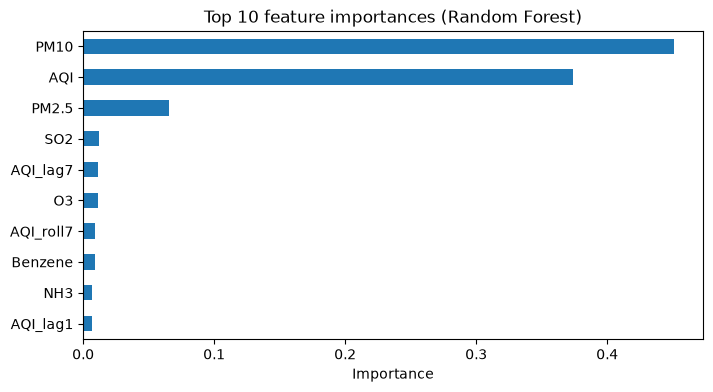

In [30]:
rf = final_model.named_steps["randomforestregressor"]
importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

print(importance.head(10).round(3))

importance.head(10).sort_values().plot(kind="barh", figsize=(8, 4),
                                       title="Top 10 feature importances (Random Forest)")
plt.xlabel("Importance")
plt.show()

In [32]:
day = "2020-03-04"   # change to any date in Jan-Jun 2020 (a day before 2020-06-30)
row = test[test["Date"] == day]

pred = final_model.predict(row[features])[0]
print("Date:", day)
print("Today's AQI:", row["AQI"].iloc[0])
print("Model's prediction for tomorrow:", round(pred, 1))
print("Actual AQI tomorrow:", row["target"].iloc[0])

Date: 2020-03-04
Today's AQI: 106.0
Model's prediction for tomorrow: 101.2
Actual AQI tomorrow: 113.0
